C:\Users\Balag\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - accuracy: 0.2222 - loss: 1.1533 - val_accuracy: 0.5000 - val_loss: 1.0751
Epoch 2/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4074 - loss: 1.0535 - val_accuracy: 0.5833 - val_loss: 1.0209
Epoch 3/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6574 - loss: 0.9710 - val_accuracy: 0.5833 - val_loss: 0.9712
Epoch 4/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6759 - loss: 0.8894 - val_accuracy: 0.5833 - val_loss: 0.9248
Epoch 5/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6759 - loss: 0.8124 - val_accuracy: 0.5833 - val_loss: 0.8802
Epoch 6/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6759 - loss: 0.7399 - val_accuracy: 0.5833 - val_loss: 0.8377
Epoch 7/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6759 - loss: 0.6711 - val_accuracy: 0.5833 - val_loss: 0.7993
Epoch 8/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6759 - loss: 0.6175 - val_accuracy: 0.5833 - val_lo

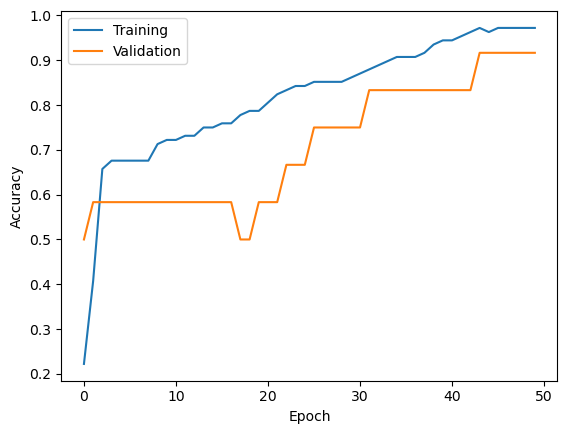

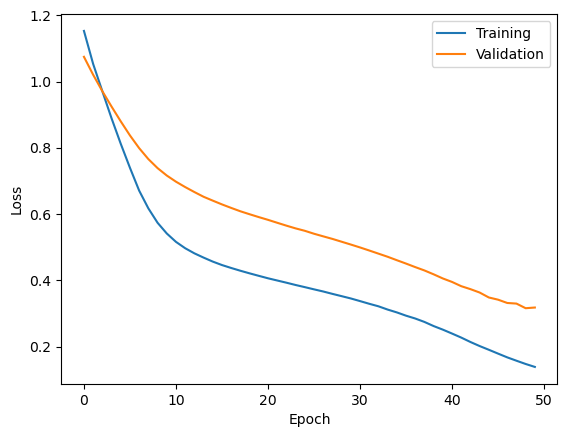

Sepal Length:  5
Sepal Width:  5
Petal Length:  4
Petal Width:  4


Predicted Species: setosa


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

iris=load_iris()
X=iris.data
y=iris.target

scaler=StandardScaler()
X=scaler.fit_transform(X)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

model=Sequential([
    Dense(10,activation="relu",input_shape=(4,)),
    Dense(8,activation="relu"),
    Dense(3,activation="softmax")
])

model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])
history=model.fit(X_train,y_train,epochs=50,batch_size=5,validation_split=0.1,verbose=1)

loss,accuracy=model.evaluate(X_test,y_test)
print("Test Accuracy:",accuracy*100)

plt.plot(history.history["accuracy"],label="Training")
plt.plot(history.history["val_accuracy"],label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.plot(history.history["loss"],label="Training")
plt.plot(history.history["val_loss"],label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

sl=float(input("Sepal Length: "))
sw=float(input("Sepal Width: "))
pl=float(input("Petal Length: "))
pw=float(input("Petal Width: "))
sample=scaler.transform([[sl,sw,pl,pw]])
print("Predicted Species:",iris.target_names[np.argmax(model.predict(sample,verbose=0))])